In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]

import numpy as np
import arviz as az
import matplotlib.pyplot as plt
import xarray
from ICIW_Plots import figure, make_rect_ax, make_square_ax, cm2inch
from scipy.stats.qmc import LatinHypercube, scale
import jax
import jax.numpy as jnp

plt.style.use("ICIWstyle")

In [2]:
from HSA_GTMo_C_004 import (
    kinetics_model,
    calculate_partial_pressures,
    generate_synthetic_data,
    TRUE_PARAMS,
)

In [3]:
params = {
    "T": (450.0, 600.0),
    "p": (3.0, 9.0),
    "c2h": (0.2, 4.0),
    "c2m": (0.5, 1000.0),
    "c2w": (0.5, 1000.0),
    "c2i": (0.05, 1.0),
}

# Generate the space filling design points

In [4]:
num_samples = 1000
LHsampler = LatinHypercube(d=len(params))
samples = LHsampler.random(n=num_samples)
samples = scale(
    samples, [v[0] for v in params.values()], [v[1] for v in params.values()]
)

samples = xarray.DataArray(
    data=samples,
    dims=["sample", "parameter"],
    coords={"parameter": list(params.keys())},
)
display(samples)

<xarray.DataArray (sample: 1000, parameter: 6)> Size: 48kB
array([[4.57885204e+02, 3.04044367e+00, 1.77429455e+00, 7.57739332e+02,
        7.82113568e+02, 5.23885293e-01],
       [5.62666662e+02, 4.75564824e+00, 3.03617684e+00, 4.15966184e+02,
        6.45955105e+02, 8.05166342e-01],
       [5.57849389e+02, 6.33370035e+00, 2.05862543e+00, 4.36933614e+02,
        9.41875222e+02, 6.64242601e-01],
       ...,
       [5.26664842e+02, 8.16876826e+00, 3.94167649e+00, 8.69957690e+02,
        7.88965413e+02, 9.87688857e-01],
       [5.68469724e+02, 4.25770724e+00, 3.00536397e+00, 1.44102093e+02,
        4.44833335e+02, 5.51364473e-01],
       [5.72393483e+02, 4.43709151e+00, 2.94217865e+00, 5.81072947e+01,
        4.19001630e+02, 9.15556134e-01]], shape=(1000, 6))
Coordinates:
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
Dimensions without coordinates: sample

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/stats/density_utils.py:250: RuntimeWarning: divide by zero encountered in scalar power
  out = t - (2 * N * np.pi**0.5 * f) ** (-0.4)


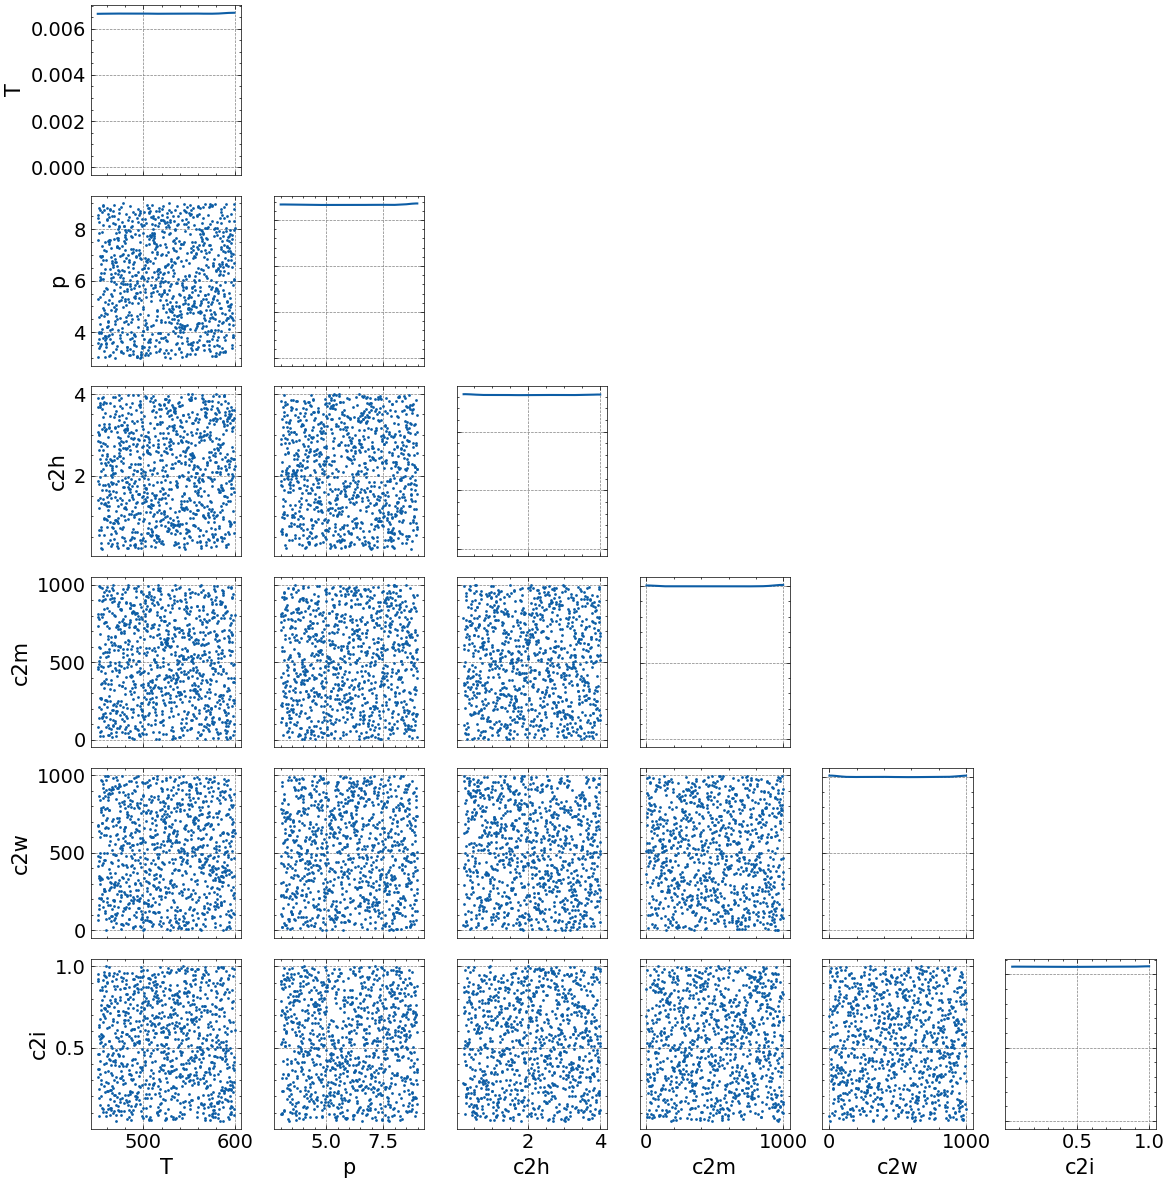

In [5]:
# Convert samples to a format suitable for arviz pair plot
sample_dict = {param: samples.sel(parameter=param).values for param in params.keys()}

az.plot_pair(sample_dict, kind="scatter", marginals=True, figsize=(12, 12))
plt.tight_layout()
plt.show()

Pretty space filling!

## Generate the GT model predictions at these positions

In [6]:
T, p, lat_r = generate_synthetic_data(
    jnp.array(samples.sel(parameter="T").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="p").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2h").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2m").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2w").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2i").values).reshape(-1, 1),
    rel_noise_std=0.0,
)
T, p, obs_r = generate_synthetic_data(
    jnp.array(samples.sel(parameter="T").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="p").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2h").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2m").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2w").values).reshape(-1, 1),
    jnp.array(samples.sel(parameter="c2i").values).reshape(-1, 1),
    rel_noise_std=0.1,
)

In [7]:
print(obs_r.shape)

(10, 1000, 1, 1)


array([[<Axes: title={'center': 'lat_r'}>,
        <Axes: title={'center': 'obs_r'}>]], dtype=object)

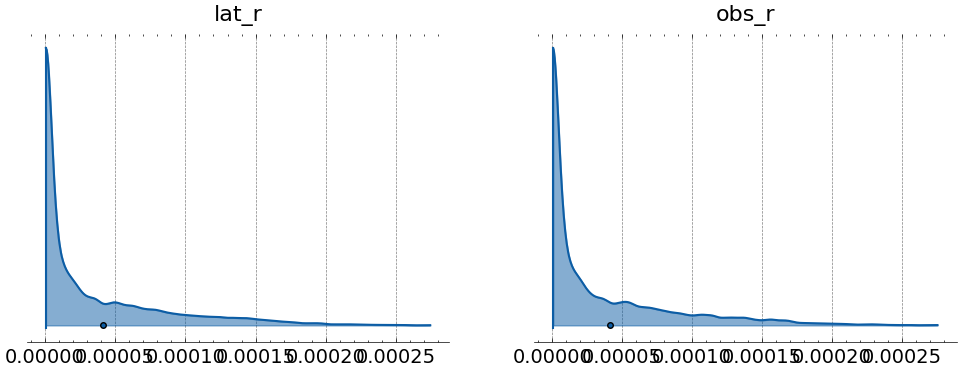

In [8]:
az.plot_density(
    {
        "lat_r": lat_r.flatten(),
        "obs_r": obs_r.flatten(),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)
# ax = plt.gca()
# ax.set_xscale("log")

array([[<Axes: title={'center': 'lat_r'}>]], dtype=object)

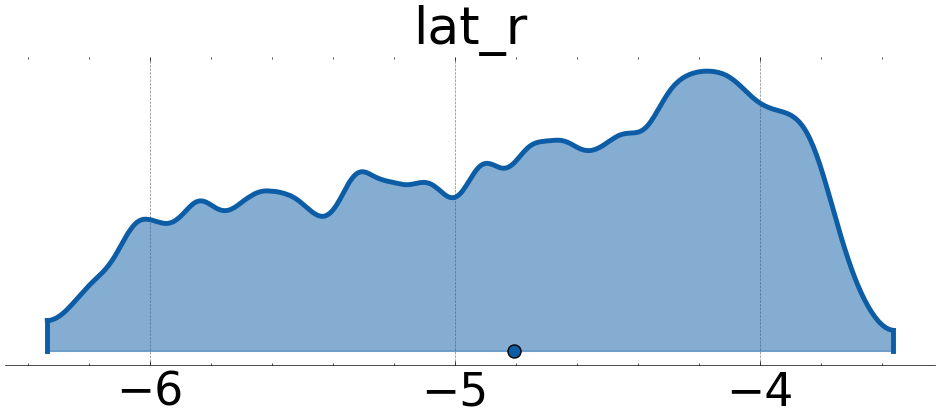

In [9]:
az.plot_density(
    {
        "lat_r": np.log10(lat_r.flatten()),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)

In [10]:
data = xarray.Dataset(
    {
        "samples": samples,
        "T": (("sample"), T.flatten()),
        "p": (("sample", "species"), p),
        "latent_r": (("time", "sample", "component", "draws"), lat_r),
        "obs_r": (("time", "sample", "component", "draws"), obs_r),
    },
    coords={
        "sample": np.arange(num_samples),
        "species": ["CO2", "H2", "H2O", "CH4", "I"],
        "time": np.arange(lat_r.shape[0]),
        "component": ["a"],
        "draws": np.arange(lat_r.shape[3]),
    },
)
data.attrs["noise"] = "homoscedastic"
data.attrs["sigma"] = 1e-5
display(data)

data.to_netcdf(Path("data/test_HSA_Da_D_004.nc"))

<xarray.Dataset> Size: 160kB
Dimensions:    (parameter: 6, sample: 1000, species: 5, time: 10, component: 1,
                draws: 1)
Coordinates:
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
  * time       (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * component  (component) <U1 4B 'a'
  * draws      (draws) int64 8B 0
Data variables:
    samples    (sample, parameter) float64 48kB 457.9 3.04 ... 419.0 0.9156
    T          (sample) float32 4kB ...
    p          (sample, species) float32 20kB ...
    latent_r   (time, sample, component, draws) float32 40kB ...
    obs_r      (time, sample, component, draws) float32 40kB ...
Attributes:
    noise:    homoscedastic
    sigma:    1e-05